In [21]:
# Required libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import seaborn as sns

# Linear model and basic functions from scikit-learn
from sklearn import datasets, linear_model
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Regression models used in the examples
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import RadiusNeighborsRegressor

In [22]:
# Load data
infile = "CBP_TWQM_MAIN_WQ_2021_2026_surface.csv"

data = pd.read_csv(infile, sep=",", low_memory=False)

# The CSV is in long format, with one row per parameter measurement.
# Pivot it to wide format so each water-quality parameter has its own column.
data_pivot = data.pivot_table(
    index=["SampleDate", "FieldActivityId"],
    columns="Parameter",
    values="MeasureValue",
    aggfunc="mean"
).reset_index()

print("Original data shape:", data.shape)
print("Pivoted data shape:", data_pivot.shape)
data_pivot.head()

Original data shape: (1223, 29)
Pivoted data shape: (42, 29)


Parameter,SampleDate,FieldActivityId,CHLA,DIN,DO,DON,DOP,KD,NH4F,NO23F,...,SECCHI,SIGMA_T,SPCOND,TDN,TDP,TN,TON,TP,TSS,WTEMP
0,2021-10-05,608240,7.595,0.270,7.3,0.260,0.00940,0.9170,0.016,0.254,...,1.4,3.82561,14700.0,0.53,0.0131,0.747,0.477,0.0346,3.8,23.3
1,2021-11-17,608260,17.444,0.444,10.4,0.286,0.02370,1.0270,0.009,0.435,...,1.6,6.71673,16300.0,0.73,0.0271,0.922,0.478,0.0486,6.8,12.8
2,2021-12-08,608274,12.935,0.332,10.2,0.228,0.00705,0.7500,0.032,0.300,...,1.6,9.15105,20200.0,0.56,0.0096,0.736,0.404,0.0282,7.2,9.2
3,2022-03-15,611589,20.292,0.482,11.9,0.278,0.00355,0.0000,0.010,0.472,...,1.2,7.38314,16300.0,0.76,0.0061,1.072,0.590,0.0243,4.8,6.6
4,2022-04-12,699206,29.904,0.422,11.4,0.328,0.00460,1.0714,0.021,0.401,...,1.0,6.39514,15000.0,0.75,0.0088,1.104,0.682,0.0357,10.0,10.3


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1223 entries, 0 to 1222
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Station                1223 non-null   object 
 1   FieldActivityId        1223 non-null   int64  
 2   Cruise                 1223 non-null   object 
 3   Program                1223 non-null   object 
 4   Project                1223 non-null   object 
 5   DataCollector          1223 non-null   object 
 6   DataProvider           1223 non-null   object 
 7   Latitude               1223 non-null   float64
 8   Longitude              1223 non-null   float64
 9   SampleDate             1223 non-null   object 
 10  SampleTime             1223 non-null   object 
 11  TotalDepthM            1223 non-null   float64
 12  UpperPycnoclineDepthM  1022 non-null   float64
 13  LowerPycnoclineDepthM  1022 non-null   float64
 14  SampleDepthM           1223 non-null   float64
 15  Laye

In [6]:
data.columns

Index(['Station', 'FieldActivityId', 'Cruise', 'Program', 'Project',
       'DataCollector', 'DataProvider', 'Latitude', 'Longitude', 'SampleDate',
       'SampleTime', 'TotalDepthM', 'UpperPycnoclineDepthM',
       'LowerPycnoclineDepthM', 'SampleDepthM', 'Layer', 'SampleType',
       'SampleReplicate', 'Parameter', 'Qualifier', 'MeasureValue',
       'MeasureUnit', 'Method', 'Lab', 'Problem', 'PrecisionPC', 'BiasPC',
       'Details', 'TierLevel'],
      dtype='object')

In [7]:
data.describe

<bound method NDFrame.describe of      Station  FieldActivityId  Cruise Program Project DataCollector  \
0     CB4.1C           785801  BAY900    TWQM    MAIN         MDDNR   
1     CB4.1C           785781  BAY898    TWQM    MAIN         MDDNR   
2     CB4.1C           785724  BAY895    TWQM    MAIN         MDDNR   
3     CB4.1C           785723  BAY894    TWQM    MAIN         MDDNR   
4     CB4.1C           785680  BAY893    TWQM    MAIN         MDDNR   
...      ...              ...     ...     ...     ...           ...   
1218  CB4.1C           699206  BAY814    TWQM    MAIN         MDDNR   
1219  CB4.1C           611589  BAY812    TWQM    MAIN         MDDNR   
1220  CB4.1C           608274  BAY806    TWQM    MAIN         MDDNR   
1221  CB4.1C           608260  BAY805    TWQM    MAIN         MDDNR   
1222  CB4.1C           608240  BAY802    TWQM    MAIN         MDDNR   

     DataProvider  Latitude  Longitude  SampleDate  ... Qualifier  \
0           MDDNR  38.82593  -76.39945  2025

In [8]:
data.describe()

,FieldActivityId,Latitude,Longitude,TotalDepthM,UpperPycnoclineDepthM,LowerPycnoclineDepthM,SampleDepthM,MeasureValue,PrecisionPC,BiasPC,Details
count,1223.000000,1.223000e+03,1.223000e+03,1223.000000,1022.000000,1022.000000,1223.000000,1223.000000,0.0,0.0,0.0
mean,683991.873262,3.882593e+01,-7.639945e+01,31.965168,6.754795,15.912916,0.482829,682.520790,NaN,NaN,NaN
std,60983.858976,4.691500e-13,1.634917e-12,0.864359,3.580874,3.726805,0.091090,3712.242591,NaN,NaN,NaN
min,608240.000000,3.882593e+01,-7.639945e+01,30.400000,0.700000,4.500000,0.000000,-0.001050,NaN,NaN,NaN
25%,625871.000000,3.882593e+01,-7.639945e+01,31.000000,3.500000,13.500000,0.500000,0.018400,NaN,NaN,NaN
50%,670930.000000,3.882593e+01,-7.639945e+01,32.000000,6.500000,16.500000,0.500000,0.447500,NaN,NaN,NaN
75%,699303.000000,3.882593e+01,-7.639945e+01,32.600000,9.500000,18.500000,0.500000,4.800000,NaN,NaN,NaN
max,785833.000000,3.882593e+01,-7.639945e+01,33.500000,14.500000,21.500000,0.500000,28200.000000,NaN,NaN,NaN


In [9]:
#unique variables
variables =data['Parameter'].unique()
print(variables)

['CHLA' 'DIN' 'DO' 'DON' 'DOP' 'KD' 'NH4F' 'NO23F' 'NO2F' 'NO3F' 'PC' 'PH'
 'PHEO' 'PN' 'PO4F' 'PP' 'SALINITY' 'SECCHI' 'SIGMA_T' 'SPCOND' 'TDN'
 'TDP' 'TN' 'TON' 'TP' 'TSS' 'WTEMP']


In [12]:
#listing all functions from scikit learn 
options = [item for item in dir(linear_model) if not item.startswith("_")]
print(options)

['ARDRegression', 'BayesianRidge', 'ElasticNet', 'ElasticNetCV', 'GammaRegressor', 'HuberRegressor', 'Lars', 'LarsCV', 'Lasso', 'LassoCV', 'LassoLars', 'LassoLarsCV', 'LassoLarsIC', 'LinearRegression', 'LogisticRegression', 'LogisticRegressionCV', 'MultiTaskElasticNet', 'MultiTaskElasticNetCV', 'MultiTaskLasso', 'MultiTaskLassoCV', 'OrthogonalMatchingPursuit', 'OrthogonalMatchingPursuitCV', 'PassiveAggressiveClassifier', 'PassiveAggressiveRegressor', 'Perceptron', 'PoissonRegressor', 'QuantileRegressor', 'RANSACRegressor', 'Ridge', 'RidgeCV', 'RidgeClassifier', 'RidgeClassifierCV', 'SGDClassifier', 'SGDOneClassSVM', 'SGDRegressor', 'TheilSenRegressor', 'TweedieRegressor', 'enet_path', 'lars_path', 'lars_path_gram', 'lasso_path', 'orthogonal_mp', 'orthogonal_mp_gram', 'ridge_regression']


The target variable I will be using is CHL-A, due to the biological and chemcial implications it can have on water quality. My input variables will be dissolved oxygen (a good proxy on photosynthetic activity), water temprature (phytoplankton metablic processes), total nitrogen (nutrient loading impacts the amount of oxyegn through biological uptake), secchi depth and total suspended solids (determine light penetration for phytoplankton). 

y = 0.17 * x + 10.41
Mean squared error: 43.51
R-squared: -0.07


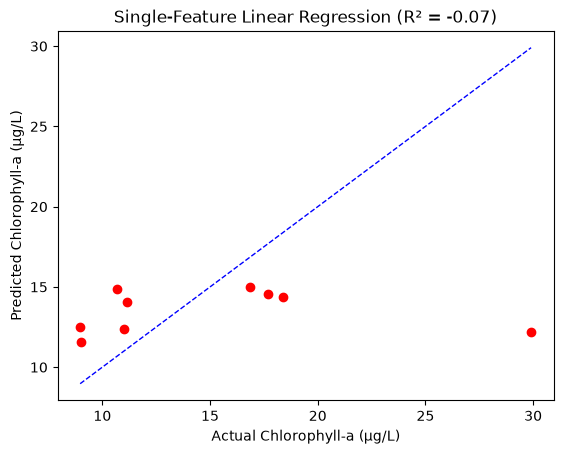

In [23]:
# Simple input variable (water temperature) and one target variable (chl-a)
# This follows the single-feature Linear Regression example.
data_clean = data_pivot.dropna(subset=["CHLA", "WTEMP"]).copy()

X = data_clean[["WTEMP"]].values
y = data_clean["CHLA"].values

# Split data into training/testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=4
)

# Create and train the linear regression model
regr = linear_model.LinearRegression()
regr.fit(X_train, y_train)

# make predictions using the testing set
y_pred = regr.predict(X_test)

# Evaluate model performance
print("y = %.2f * x + %.2f" % (regr.coef_[0], regr.intercept_))
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print("R-squared: %.2f" % r2_score(y_test, y_pred))

# plot actual versus predicted values
plt.scatter(y_test, y_pred, color="red")
line_min = min(y_test.min(), y_pred.min())
line_max = max(y_test.max(), y_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], "--", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a (µg/L)")
plt.ylabel("Predicted Chlorophyll-a (µg/L)")
plt.title("Single-Feature Linear Regression (R² = %.2f)" % r2_score(y_test, y_pred))
plt.show()

The plot compares actual chlorophyll-a measurements with predictions based only on water temperature. Points closer to the blue dashed line indicate more accurate predictions. The R-squared and mean squared error printed above summarize how well this single predictor performs on the test data. The relationship of a -0.07 R sqaured value and a MSE of 43.51 show a low trend in the one parameter.

Multiple Linear Regression
Mean squared error: 33.37
R-squared: 0.18
Input features: ['DO', 'WTEMP', 'TN', 'SECCHI', 'TSS']


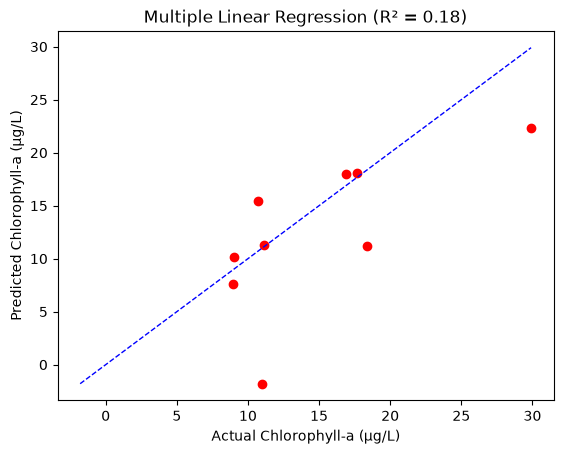

In [24]:
# target and multiple input features
target = "CHLA"
features = ["DO", "WTEMP", "TN", "SECCHI", "TSS"]

# Keep the same rows for all three regression models below.
data_model = data_pivot.dropna(subset=[target] + features).copy()

X = data_model[features].values
y = data_model[target].values

# Use one train/test split for each model comparison
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)

# Create and train multiple linear regression
regr = linear_model.LinearRegression()
regr.fit(X_train, y_train)
y_pred = regr.predict(X_test)

# Evaluate model
print("Multiple Linear Regression")
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred))
print("R-squared: %.2f" % r2_score(y_test, y_pred))
print("Input features:", features)

# Plot actual versus predicted values
plt.scatter(y_test, y_pred, color="red")
line_min = min(y_test.min(), y_pred.min())
line_max = max(y_test.max(), y_pred.max())
plt.plot([line_min, line_max], [line_min, line_max], "--", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a (µg/L)")
plt.ylabel("Predicted Chlorophyll-a (µg/L)")
plt.title("Multiple Linear Regression (R² = %.2f)" % r2_score(y_test, y_pred))
plt.show()

This plot compares the actual chlorophyll-a values with the values predicted from all five input variables. Points close to the blue dashed line indicate predictions close to the measurements. Using multiple inputs allows the model to consider several water-quality conditions at once, but it does not guarantee better predictions. The R-sqaure value of 0.18 and lower MSE of 33.37 shows that this multiple linear regression would be a better model fit.

K-Nearest Neighbors (k = 7)
Mean squared error: 32.45
R-squared: 0.20


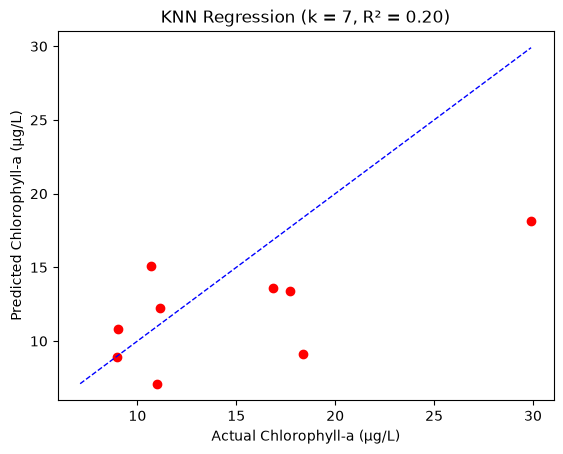

In [35]:
# K-Nearest Neighbors (KNN) Regression

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

k = 7

knn_reg = make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=k))

knn_reg.fit(X_train, y_train)
y_pred_knn = knn_reg.predict(X_test)

print("K-Nearest Neighbors (k = %d)" % k)
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred_knn))
print("R-squared: %.2f" % r2_score(y_test, y_pred_knn))

# Plot actual versus predicted values
plt.scatter(y_test, y_pred_knn, color="red")
line_min = min(y_test.min(), y_pred_knn.min())
line_max = max(y_test.max(), y_pred_knn.max())
plt.plot([line_min, line_max], [line_min, line_max], "--", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a (µg/L)")
plt.ylabel("Predicted Chlorophyll-a (µg/L)")
plt.title("KNN Regression (k = %d, R² = %.2f)" % (k, r2_score(y_test, y_pred_knn)))
plt.show()

I chosek=7 for the KNN model because it provided the best prediction compared to the other values of k tested. Using seven neighboring observations allows the model to account for local patterns in the water-quality data while reducing the influence of individual measurements. This balance may help the model make more reliable predictions of chlorophyll-a concentrations.

Multiple Linear Regression R-squared: 0.18
KNN Regression R-squared: 0.37


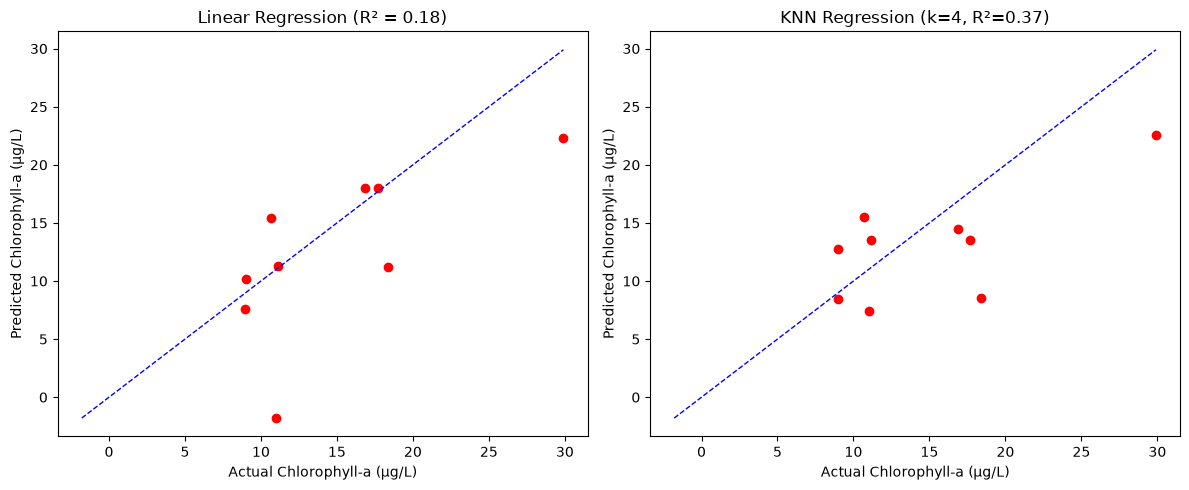

In [26]:
# Compare the two models above using the same held-out test observations.
# The MLP model is added in the next section.
print("Multiple Linear Regression R-squared: %.2f" % r2_score(y_test, regr.predict(X_test)))
print("KNN Regression R-squared: %.2f" % r2_score(y_test, y_pred_knn))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(y_test, regr.predict(X_test), color="red")
line_min = min(y_test.min(), regr.predict(X_test).min(), y_pred_knn.min())
line_max = max(y_test.max(), regr.predict(X_test).max(), y_pred_knn.max())
plt.plot([line_min, line_max], [line_min, line_max], "--", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a (µg/L)")
plt.ylabel("Predicted Chlorophyll-a (µg/L)")
plt.title("Linear Regression (R² = %.2f)" % r2_score(y_test, regr.predict(X_test)))

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_knn, color="red")
plt.plot([line_min, line_max], [line_min, line_max], "--", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a (µg/L)")
plt.ylabel("Predicted Chlorophyll-a (µg/L)")
plt.title("KNN Regression (k=%d, R²=%.2f)" % (k, r2_score(y_test, y_pred_knn)))

plt.tight_layout()
plt.show()

MLP Regressor (10 hidden nodes)
Mean squared error: 22.04
R-squared: 0.46


/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


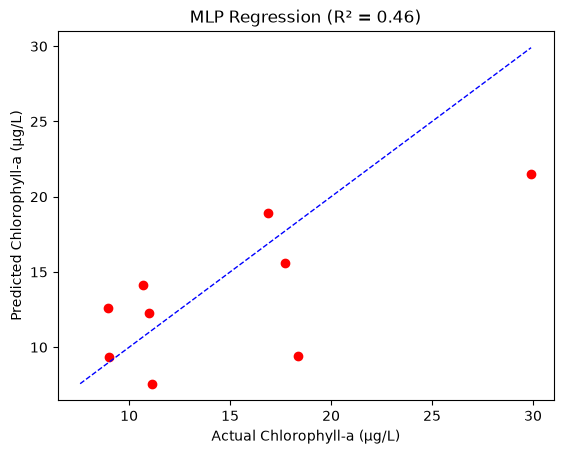

In [27]:
# Multi-Layer Perceptron (MLP) Regression
# Standardize the input variables before fitting the neural network.
# One hidden layer with 10 nodes is a simple starting architecture.

regr_mlp = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(10,),
        random_state=3,
        max_iter=2000
    )
)

# Train the model using the same training set
regr_mlp.fit(X_train, y_train)

# Make predictions using the same testing set
y_pred_mlp = regr_mlp.predict(X_test)

# Evaluate model performance
print("MLP Regressor (10 hidden nodes)")
print("Mean squared error: %.2f" % mean_squared_error(y_test, y_pred_mlp))
print("R-squared: %.2f" % r2_score(y_test, y_pred_mlp))

# Plot actual versus predicted values
plt.scatter(y_test, y_pred_mlp, color="red")
line_min = min(y_test.min(), y_pred_mlp.min())
line_max = max(y_test.max(), y_pred_mlp.max())
plt.plot([line_min, line_max], [line_min, line_max], "--", color="blue", linewidth=1)
plt.xlabel("Actual Chlorophyll-a (µg/L)")
plt.ylabel("Predicted Chlorophyll-a (µg/L)")
plt.title("MLP Regression (R² = %.2f)" % r2_score(y_test, y_pred_mlp))
plt.show()

The MLP regression model uses a neural network with one hidden layer containing 10 nodes to predict Chl-a concentrations from the selected water quality variables. The scatter plot compares the actual Chl-a values with the predicted values from the model. The dashed blue line represents perfect agreement between actual and predicted values. Points closer to this line indicate more accurate predictions. The R squared score measures how well the model predicts Chl-a concentrations, with values closer to 1 indicating better model performance. The R sqaured value of 0.46 shows a stronger relationship than the post models but still, a weak relationship. The MLP model's performance can be compared with the linear regression and K-nearest neighbors models to determine which technique predicts Chl-a most accurately.

From all of these models, The MLP Regressor performed the best out of the three main models, with an R sqaured of 0.46 and a mean squared error of 22.04. This indicates that the model explained approximately 46% of the variation in chlorophyll-a concentrations and had the lowest error compared with KNN and multiple linear regression. Overall, the MLP was the best performing model in this comparison, although further testing could help determine how reliable its predictions are.

I would expect the MLP Regressor to perform well because chl-a concentrations can be influenced by several water quality variables at the same time, including dissolved oxygen, nitrogen, water temperature, water clarity, and suspended solids. These relationships may be nonlinear, meaning they cannot always be described by a straight line. The MLP can learn more complex relationships between these variables, which may explain why it performed better than KNN and multiple linear regression.